In [45]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

In [46]:
t = sp.Symbol('t')
x = sp.Function('x')(t)

In [47]:
m_val = 1
x0_val = 0.1
v0_val = 0
k_values = [1, 4, 9, 16, 25]

In [48]:
k_sym = sp.Symbol('k', positive=True)
eq_obsh = m_val * x.diff(t, 2) + k_sym * x
obsh_sol = sp.dsolve(eq_obsh, x)
print(f"Решение в общем виде: x(t) = {obsh_sol.rhs}")

Решение в общем виде: x(t) = C1*sin(sqrt(k)*t) + C2*cos(sqrt(k)*t)


In [49]:
solutions = {}
for k in k_values:
    eq = m_val * x.diff(t, 2) + k * x
    ics = {x.subs(t, 0): x0_val, x.diff(t).subs(t, 0): v0_val}
    part_sol = sp.dsolve(eq, x, ics=ics)
    solutions[k] = part_sol.rhs
    print(f"Частное решение для k = {k}: x(t) = {part_sol.rhs}")

Частное решение для k = 1: x(t) = 0.1*cos(t)
Частное решение для k = 4: x(t) = 0.1*cos(2*t)
Частное решение для k = 9: x(t) = 0.1*cos(3*t)
Частное решение для k = 16: x(t) = 0.1*cos(4*t)
Частное решение для k = 25: x(t) = 0.1*cos(5*t)


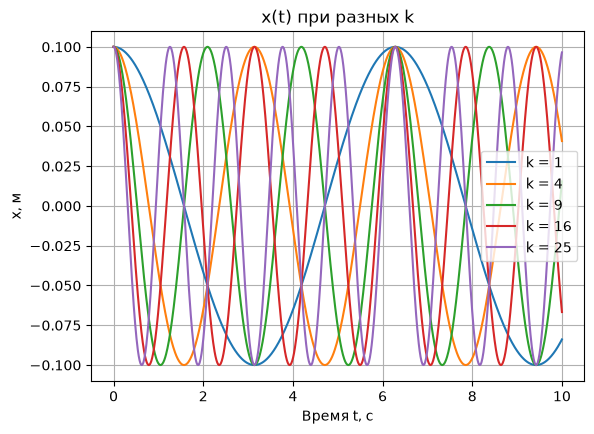

In [50]:
t_arr = np.linspace(0, 10, 1000)

plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
for k in k_values:
    x_func = sp.lambdify(t, solutions[k], 'numpy')
    plt.plot(t_arr, x_func(t_arr), label=f'k = {k}')
plt.title('x(t) при разных k')
plt.xlabel('Время t, с')
plt.ylabel('x, м')
plt.grid(True)
plt.legend()

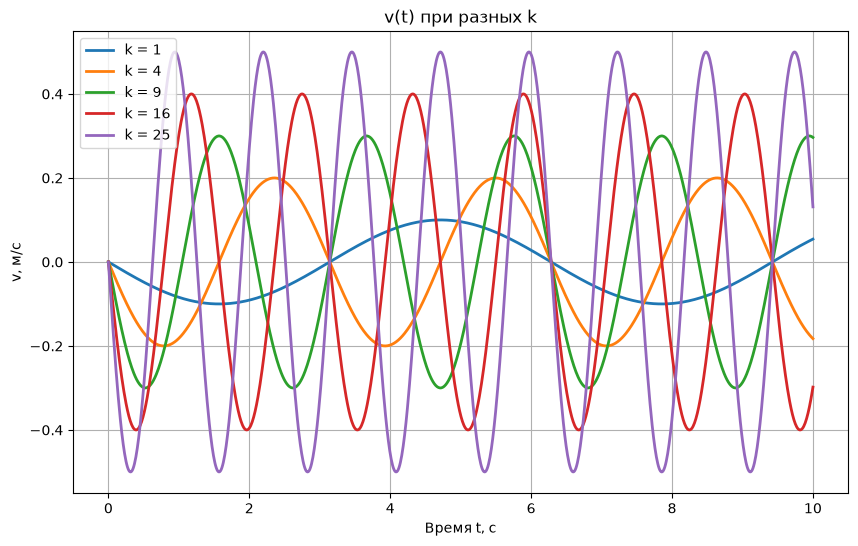

In [51]:
plt.figure(figsize=(10, 6))

for k in k_values:
    v_expr = sp.diff(solutions[k], t)
    
    v_func = sp.lambdify(t, v_expr, 'numpy')
    
    plt.plot(t_arr, v_func(t_arr), label=f'k = {k}', linewidth=2)

plt.title('v(t) при разных k')
plt.xlabel('Время t, с')
plt.ylabel('v, м/с')
plt.grid(True)
plt.legend()
plt.show()

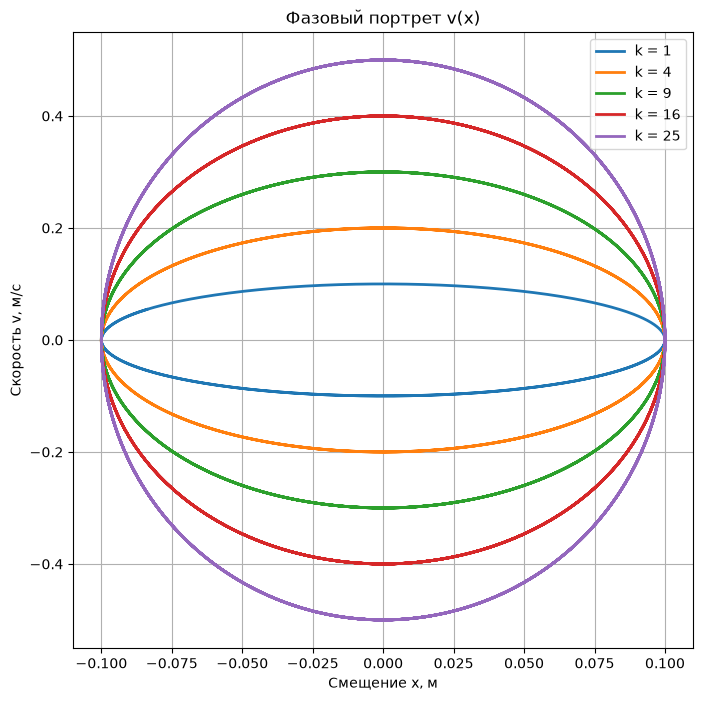

In [52]:
plt.figure(figsize=(8, 8))

for k in k_values:
    x_func = sp.lambdify(t, solutions[k], 'numpy')
    
    v_formula = sp.diff(solutions[k], t)
    v_func = sp.lambdify(t, v_formula, 'numpy')
    
    plt.plot(x_func(t_arr), v_func(t_arr), label=f'k = {k}', linewidth=2)

plt.title('Фазовый портрет v(x)')
plt.xlabel('Смещение x, м')
plt.ylabel('Скорость v, м/с')
plt.grid(True)
plt.legend()
plt.show()

Как период колебаний зависит от k?
Чем жестче пружина, тем чаще совершаются колебания.

При массе m = 1 расчет по формуле T = 2pi*sqrt(m/k) чётко совпадает с первым графиком. Например, при k = 1 период равен примерно 6.28, а при k = 4 период уменьшается в два раза и равен примерно 3.14. Рисунок это подтверждает.

Зависит ли амплитуда колебаний от k при данных начальных условиях?
Нет, т.к. по графику 2 видно, что при любом k амплитуда всех линий одинакова и равна 0.1 м.